# Chinook SQL Analysis
Task 5 - Elevvo Data Analytics Internship

In this notebook I use SQL to analyse the sales of a digital music store using the Chinook database (SQLite). I want to answer 3 business questions:
1. What are the top-selling products?
2. How much revenue comes from each region?
3. How do sales perform month by month?

Tools: SQLite, Python (pandas, matplotlib, seaborn)

In [1]:
import sqlite3
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

url = "https://github.com/lerocha/chinook-database/raw/master/ChinookDatabase/DataSources/Chinook_Sqlite.sqlite"
urllib.request.urlretrieve(url, "chinook.db")
conn = sqlite3.connect("chinook.db")

def sql(query):
    return pd.read_sql(query, conn)

## The database

In [2]:
sql("SELECT name FROM sqlite_master WHERE type = 'table'")

,name
0,Album
1,Artist
2,Customer
3,Employee
4,Genre
5,Invoice
6,InvoiceLine
7,MediaType
8,Playlist
9,PlaylistTrack


In [3]:
for t in ["Invoice", "InvoiceLine", "Track", "Album", "Artist", "Genre", "Customer"]:
    print(t, "->", ", ".join(sql(f"SELECT * FROM {t} LIMIT 1").columns))

Invoice -> InvoiceId, CustomerId, InvoiceDate, BillingAddress, BillingCity, BillingState, BillingCountry, BillingPostalCode, Total
InvoiceLine -> InvoiceLineId, InvoiceId, TrackId, UnitPrice, Quantity
Track -> TrackId, Name, AlbumId, MediaTypeId, GenreId, Composer, Milliseconds, Bytes, UnitPrice
Album -> AlbumId, Title, ArtistId
Artist -> ArtistId, Name
Genre -> GenreId, Name
Customer -> CustomerId, FirstName, LastName, Company, Address, City, State, Country, PostalCode, Phone, Fax, Email, SupportRepId


Sales are stored in **Invoice** (one row per order, with the billing country and total) and **InvoiceLine** (one row per track sold). The products are the **Tracks**, which connect to **Album**, **Artist** and **Genre**. So to analyse product sales I need to JOIN these tables together.

In [4]:
q = """
SELECT COUNT(*) AS invoices,
COUNT(DISTINCT CustomerId) AS customers,
MIN(DATE(InvoiceDate)) AS first_sale,
MAX(DATE(InvoiceDate)) AS last_sale,
ROUND(SUM(Total), 2) AS total_revenue
FROM Invoice
"""
sql(q)

,invoices,customers,first_sale,last_sale,total_revenue
0,412,59,2021-01-01,2025-12-22,2328.6


## 1. Top-selling products
First the top tracks. I join InvoiceLine with Track, Album, Artist and Genre to get the full product info for each sale.

In [5]:
q = """
SELECT t.Name AS track,
ar.Name AS artist,
g.Name AS genre,
SUM(il.Quantity) AS units_sold,
ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Album al ON t.AlbumId = al.AlbumId
JOIN Artist ar ON al.ArtistId = ar.ArtistId
JOIN Genre g ON t.GenreId = g.GenreId
GROUP BY t.TrackId
ORDER BY revenue DESC, units_sold DESC
LIMIT 10
"""
sql(q)

,track,artist,genre,units_sold,revenue
0,The Woman King,Battlestar Galactica,Science Fiction,2,3.98
1,The Fix,Heroes,Drama,2,3.98
2,Walkabout,Lost,TV Shows,2,3.98
3,Hot Girl,The Office,TV Shows,2,3.98
4,Gay Witch Hunt,The Office,TV Shows,2,3.98
5,Phyllis's Wedding,The Office,Comedy,2,3.98
6,How to Stop an Exploding Man,Heroes,Drama,2,3.98
7,Pilot,Aquaman,TV Shows,2,3.98
8,Occupation / Precipice,Battlestar Galactica,TV Shows,1,1.99
9,"Exodus, Pt. 1",Battlestar Galactica,TV Shows,1,1.99


No track was sold more than 2 times, so single tracks don't say much. The top ones are TV show episodes because they cost 1.99 instead of 0.99. It makes more sense to look at bigger groups: genres, artists and albums.

In [6]:
q = """
SELECT g.Name AS genre,
SUM(il.Quantity) AS units_sold,
ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue,
ROUND(100.0 * SUM(il.UnitPrice * il.Quantity) / (SELECT SUM(Total) FROM Invoice), 1) AS revenue_pct
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Genre g ON t.GenreId = g.GenreId
GROUP BY g.Name
ORDER BY revenue DESC
LIMIT 10
"""
genres = sql(q)
genres

,genre,units_sold,revenue,revenue_pct
0,Rock,835,826.65,35.5
1,Latin,386,382.14,16.4
2,Metal,264,261.36,11.2
3,Alternative & Punk,244,241.56,10.4
4,TV Shows,47,93.53,4.0
5,Jazz,80,79.20,3.4
6,Blues,61,60.39,2.6
7,Drama,29,57.71,2.5
8,R&B/Soul,41,40.59,1.7
9,Classical,41,40.59,1.7


In [7]:
q = """
SELECT ar.Name AS artist,
SUM(il.Quantity) AS units_sold,
ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Album al ON t.AlbumId = al.AlbumId
JOIN Artist ar ON al.ArtistId = ar.ArtistId
GROUP BY ar.Name
ORDER BY revenue DESC
LIMIT 10
"""
artists = sql(q)
artists

,artist,units_sold,revenue
0,Iron Maiden,140,138.60
1,U2,107,105.93
2,Metallica,91,90.09
3,Led Zeppelin,87,86.13
4,Lost,41,81.59
5,The Office,25,49.75
6,Os Paralamas Do Sucesso,45,44.55
7,Deep Purple,44,43.56
8,Faith No More,42,41.58
9,Eric Clapton,40,39.60


In [8]:
q = """
SELECT al.Title AS album,
ar.Name AS artist,
SUM(il.Quantity) AS units_sold,
ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Album al ON t.AlbumId = al.AlbumId
JOIN Artist ar ON al.ArtistId = ar.ArtistId
GROUP BY al.AlbumId
ORDER BY revenue DESC
LIMIT 10
"""
sql(q)

,album,artist,units_sold,revenue
0,"Battlestar Galactica (Classic), Season 1",Battlestar Galactica (Classic),18,35.82
1,"The Office, Season 3",The Office,16,31.84
2,Minha Historia,Chico Buarque,27,26.73
3,"Lost, Season 2",Lost,13,25.87
4,"Heroes, Season 1",Heroes,13,25.87
5,Greatest Hits,Lenny Kravitz,26,25.74
6,Unplugged,Eric Clapton,25,24.75
7,"Battlestar Galactica, Season 3",Battlestar Galactica,12,23.88
8,"Lost, Season 3",Lost,11,21.89
9,Acústico,Titãs,22,21.78


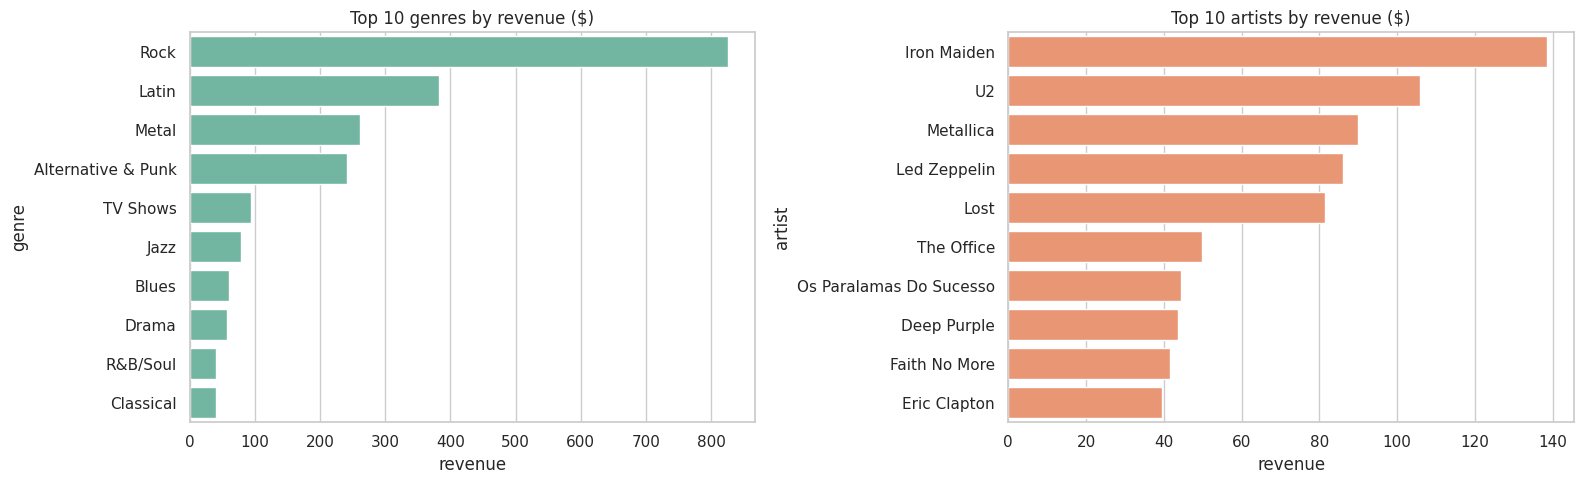

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=genres, x="revenue", y="genre", color="#66c2a5", ax=ax[0])
sns.barplot(data=artists, x="revenue", y="artist", color="#fc8d62", ax=ax[1])
ax[0].set_title("Top 10 genres by revenue ($)")
ax[1].set_title("Top 10 artists by revenue ($)")
plt.tight_layout()
plt.show()

## 2. Revenue per region
Revenue by billing country. I also rank the countries using `RANK()` (bonus: window function).

In [10]:
q = """
SELECT BillingCountry AS country,
COUNT(DISTINCT CustomerId) AS customers,
COUNT(*) AS invoices,
ROUND(SUM(Total), 2) AS revenue,
ROUND(SUM(Total) / COUNT(DISTINCT CustomerId), 2) AS revenue_per_customer,
RANK() OVER (ORDER BY SUM(Total) DESC) AS revenue_rank
FROM Invoice
GROUP BY BillingCountry
ORDER BY revenue DESC
"""
countries = sql(q)
countries

,country,customers,invoices,revenue,revenue_per_customer,revenue_rank
0,USA,13,91,523.06,40.24,1
1,Canada,8,56,303.96,37.99,2
2,France,5,35,195.10,39.02,3
3,Brazil,5,35,190.10,38.02,4
4,Germany,4,28,156.48,39.12,5
5,United Kingdom,3,21,112.86,37.62,6
6,Czech Republic,2,14,90.24,45.12,7
7,Portugal,2,14,77.24,38.62,8
8,India,2,13,75.26,37.63,9
9,Chile,1,7,46.62,46.62,10


There are 24 countries, so I also group them into bigger regions (continents) with a CASE statement:

In [11]:
q = """
SELECT CASE
WHEN BillingCountry IN ('USA', 'Canada') THEN 'North America'
WHEN BillingCountry IN ('Brazil', 'Argentina', 'Chile') THEN 'South America'
WHEN BillingCountry = 'India' THEN 'Asia'
WHEN BillingCountry = 'Australia' THEN 'Oceania'
ELSE 'Europe'
END AS region,
COUNT(DISTINCT CustomerId) AS customers,
ROUND(SUM(Total), 2) AS revenue,
ROUND(100.0 * SUM(Total) / (SELECT SUM(Total) FROM Invoice), 1) AS revenue_pct
FROM Invoice
GROUP BY region
ORDER BY revenue DESC
"""
regions = sql(q)
regions

,region,customers,revenue,revenue_pct
0,Europe,28,1114.36,47.9
1,North America,21,827.02,35.5
2,South America,7,274.34,11.8
3,Asia,2,75.26,3.2
4,Oceania,1,37.62,1.6


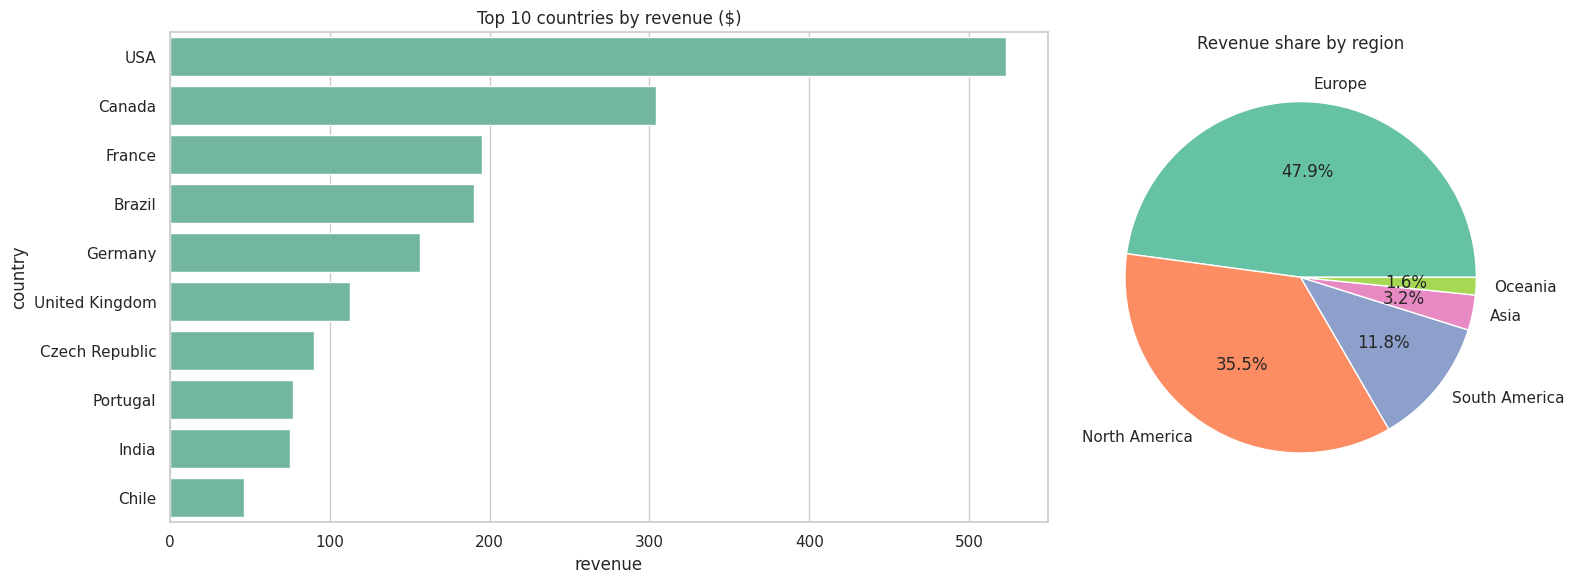

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2, 1]})
sns.barplot(data=countries.head(10), x="revenue", y="country", color="#66c2a5", ax=ax[0])
ax[0].set_title("Top 10 countries by revenue ($)")
ax[1].pie(regions["revenue"], labels=regions["region"], autopct="%1.1f%%", colors=sns.color_palette("Set2"))
ax[1].set_title("Revenue share by region")
plt.tight_layout()
plt.show()

## 3. Monthly performance
Revenue for every month, with a running total using `SUM() OVER`.

In [13]:
q = """
SELECT strftime('%Y-%m', InvoiceDate) AS month,
COUNT(*) AS invoices,
ROUND(SUM(Total), 2) AS revenue,
ROUND(SUM(SUM(Total)) OVER (ORDER BY strftime('%Y-%m', InvoiceDate)), 2) AS running_total
FROM Invoice
GROUP BY month
ORDER BY month
"""
monthly = sql(q)
print(len(monthly), "months")
monthly.head(12)

60 months


,month,invoices,revenue,running_total
0,2021-01,6,35.64,35.64
1,2021-02,7,37.62,73.26
2,2021-03,7,37.62,110.88
3,2021-04,7,37.62,148.50
4,2021-05,7,37.62,186.12
5,2021-06,7,37.62,223.74
6,2021-07,7,37.62,261.36
7,2021-08,7,37.62,298.98
8,2021-09,7,37.62,336.60
9,2021-10,7,37.62,374.22


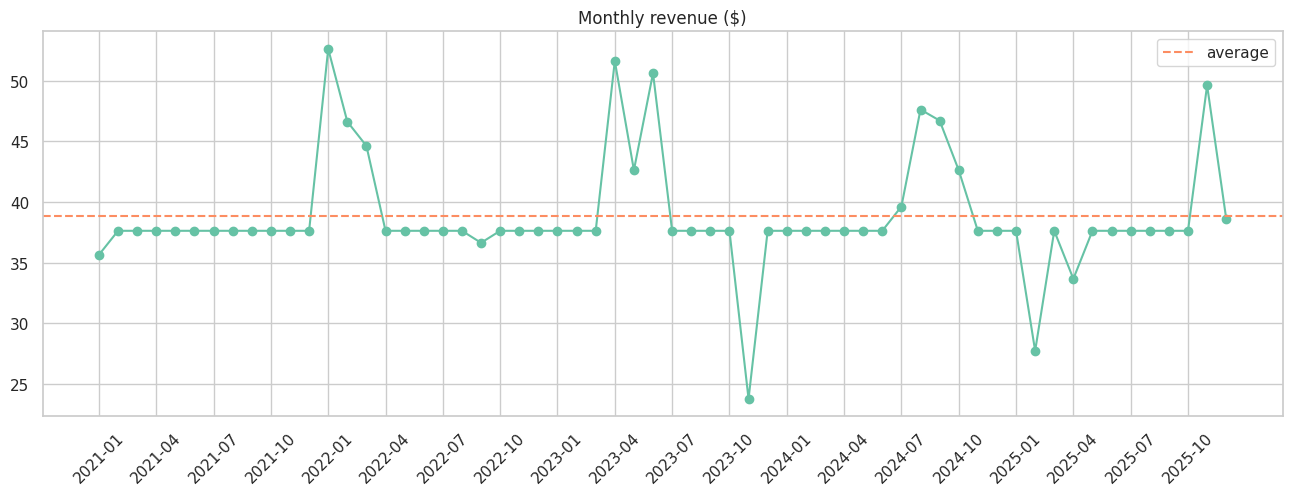

best months:
      month  revenue
12  2022-01    52.62
27  2023-04    51.62
29  2023-06    50.62

worst months:
      month  revenue
34  2023-11    23.76
49  2025-02    27.72
51  2025-04    33.66


In [14]:
plt.figure(figsize=(16, 5))
plt.plot(monthly["month"], monthly["revenue"], marker="o", color="#66c2a5")
plt.axhline(monthly["revenue"].mean(), color="#fc8d62", linestyle="--", label="average")
plt.xticks(monthly["month"][::3], rotation=45)
plt.title("Monthly revenue ($)")
plt.legend()
plt.show()
print("best months:")
print(monthly.nlargest(3, "revenue")[["month", "revenue"]])
print("\nworst months:")
print(monthly.nsmallest(3, "revenue")[["month", "revenue"]])

Year over year, using `LAG()` to compare each year with the one before:

In [15]:
q = """
WITH yearly AS (
SELECT strftime('%Y', InvoiceDate) AS year,
COUNT(*) AS invoices,
ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY year
)
SELECT year, invoices, revenue,
LAG(revenue) OVER (ORDER BY year) AS prev_year,
ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY year)) / LAG(revenue) OVER (ORDER BY year), 1) AS growth_pct
FROM yearly
"""
sql(q)

,year,invoices,revenue,prev_year,growth_pct
0,2021,83,449.46,NaN,NaN
1,2022,83,481.45,449.46,7.1
2,2023,83,469.58,481.45,-2.5
3,2024,83,477.53,469.58,1.7
4,2025,80,450.58,477.53,-5.6


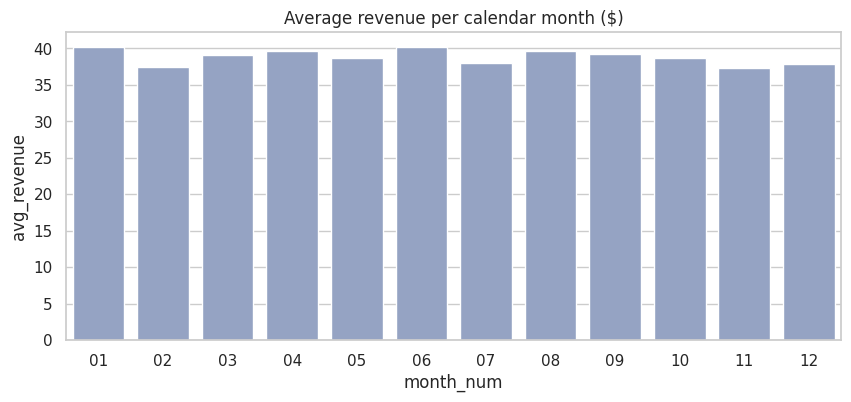

In [16]:
q = """
SELECT strftime('%m', InvoiceDate) AS month_num,
ROUND(SUM(Total) / COUNT(DISTINCT strftime('%Y', InvoiceDate)), 2) AS avg_revenue
FROM Invoice
GROUP BY month_num
"""
season = sql(q)
plt.figure(figsize=(10, 4))
sns.barplot(data=season, x="month_num", y="avg_revenue", color="#8da0cb")
plt.title("Average revenue per calendar month ($)")
plt.show()

## Bonus: window functions
I already used `RANK()`, `LAG()` and `SUM() OVER` above. Here `ROW_NUMBER()` finds the best-selling artist inside each genre:

In [17]:
q = """
WITH artist_sales AS (
SELECT g.Name AS genre,
ar.Name AS artist,
ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue,
ROW_NUMBER() OVER (PARTITION BY g.Name ORDER BY SUM(il.UnitPrice * il.Quantity) DESC) AS rn
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Genre g ON t.GenreId = g.GenreId
JOIN Album al ON t.AlbumId = al.AlbumId
JOIN Artist ar ON al.ArtistId = ar.ArtistId
GROUP BY g.Name, ar.Name
)
SELECT genre, artist AS top_artist, revenue
FROM artist_sales
WHERE rn = 1
ORDER BY revenue DESC
LIMIT 10
"""
sql(q)

,genre,top_artist,revenue
0,Metal,Metallica,90.09
1,Rock,U2,90.09
2,TV Shows,Lost,45.77
3,Latin,Os Paralamas Do Sucesso,44.55
4,Drama,Lost,35.82
5,Sci Fi & Fantasy,Battlestar Galactica (Classic),35.82
6,Alternative & Punk,Titãs,33.66
7,Blues,Eric Clapton,26.73
8,Jazz,Spyro Gyra,19.80
9,Comedy,The Office,17.91


And the top 5 customers ranked by how much they spent:

In [18]:
q = """
SELECT c.FirstName || ' ' || c.LastName AS customer,
c.Country AS country,
COUNT(i.InvoiceId) AS invoices,
ROUND(SUM(i.Total), 2) AS total_spent,
RANK() OVER (ORDER BY SUM(i.Total) DESC) AS spend_rank
FROM Customer c
JOIN Invoice i ON c.CustomerId = i.CustomerId
GROUP BY c.CustomerId
ORDER BY spend_rank
LIMIT 5
"""
sql(q)

,customer,country,invoices,total_spent,spend_rank
0,Helena Holý,Czech Republic,7,49.62,1
1,Richard Cunningham,USA,7,47.62,2
2,Luis Rojas,Chile,7,46.62,3
3,Ladislav Kovács,Hungary,7,45.62,4
4,Hugh O'Reilly,Ireland,7,45.62,4


## Insights
**Top-selling products**
- Rock is by far the biggest genre: 35.5% of all revenue ($826.65), then Latin (16.4%), Metal (11.2%) and Alternative & Punk (10.4%). These 4 genres make almost 3/4 of the sales
- Iron Maiden is the best-selling artist ($138.60), followed by U2, Metallica and Led Zeppelin
- No single track sold more than twice, so sales are spread over a lot of different tracks. TV episodes (1.99 each) are at the top of the track list and some TV seasons (Battlestar Galactica, The Office) are among the top albums

**Revenue per region**
- USA brings the most revenue ($523.06, about 22% of the total), then Canada, France, Brazil and Germany
- By continent Europe is the biggest market (47.9%), then North America (35.5%) and South America (11.8%)
- Revenue per customer is almost the same in every country ($37-46), so the difference between countries comes from the number of customers, not from how much each one spends

**Monthly performance**
- Sales are very stable: most months are exactly $37.62 (7 invoices) and yearly revenue stays between $449 and $482
- Best month was Jan 2022 ($52.62), worst was Nov 2023 ($23.76)
- There is no real seasonality and no growth (2025 was 5.6% lower than 2024)

**What the store could do:** focus marketing on rock/metal and Latin music, try to get more customers in the big markets (USA, Europe), and find ways to grow sales because revenue has been flat for 5 years.